# Figure 2 — Allele-specific expression and promoter structural variation

Panels:
- **B.** Allelic-ratio swarm plot across all four haplotypes, per chromosome (control condition)
- **C.** Structural variants in the promoter vs. allelic log2FC, colored by transposable-element class
- **D.** Case study: a cytochrome P450 gene (`Soltu.DM.06G029570`) with a haplotype-specific
  LTR insertion in its promoter and correspondingly reduced expression on that haplotype
- **E.** Désirée vs. Atlantic: allelic log2FC of haplotype pairs whose promoters are identical between the two cultivars
- **F.** Examples of allele-specific expression conserved between Désirée and Atlantic (13-LOX type II, *DWARF1*, *RIN4*)

Inputs: `clean_data/Fig2_ASE_SV_promoter_analysis/`

Supplementary panels from the same analysis are in `FigS_ASE_SV_promoter_analysis_supplement.ipynb`.

In [1]:
import polyase as poly
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.transforms as mtransforms
import seaborn as sns


.conda/envs/polyase/lib/python3.12/site-packages/sorted_nearest/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## Setup

In [2]:
DATA_DIR = "../clean_data/Fig2_ASE_SV_promoter_analysis"
OUT_DIR  = "./figures/Fig2"
import os
os.makedirs(OUT_DIR, exist_ok=True)

# chromosome x haplotype order used for Panel B's x-axis
CHR_HAP_ORDER = [f"{c:02d}.{h}" for c in range(1, 13) for h in range(1, 5)]


## Panel B — Allelic-ratio swarm plot per chromosome (control condition)

`long_cis_results_control.tsv` is the per-allele test of whether each haplotype's share of
total gene expression deviates from balanced (1/ploidy = 0.25), within the control condition
(`poly.test_allelic_ratios_within_conditions`). Each dot is one haplotype of one syntelog;
red = significantly unbalanced (FDR < 0.05, ratio difference > 0.1); faint grey lines connect
the four haplotypes of the same syntelog.

In [3]:
cis_results_control = pd.read_csv(f"{DATA_DIR}/long_cis_results_control.tsv")

# the per-replicate CPM/ratio columns hold one array per row; to_csv stringifies them as
# numpy\'s space-separated repr (no commas), so they come back from read_csv as plain text
# (e.g. "[4.9058 3.408 ...]") instead of arrays -- parse them back before any downstream
# plotting function tries to treat each replicate as its own data point
def _parse_rep_array(s):
    return np.fromstring(s.strip("[]"), sep=" ") if isinstance(s, str) else s

for col in ["ratios_rep_control", "cpm_rep_control"]:
    cis_results_control[col] = cis_results_control[col].apply(_parse_rep_array)

# chromosome number from the gene id (Soltu.DM.NNGxxxxx -> NN; older Sotub NNgxxxxx ids as fallback)
cis_results_control["chromosome"] = cis_results_control["gene_id"].str.split("DM.").str[1].str.split("G").str[0]
missing_chr = cis_results_control["chromosome"].isna()
if missing_chr.any():
    cis_results_control.loc[missing_chr, "chromosome"] = (
        cis_results_control.loc[missing_chr, "gene_id"].str.extract(r"Sotub(\d+)g\d+")[0]
    )


.conda/envs/polyase/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 10.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
.conda/envs/polyase/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 17.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


.conda/envs/polyase/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 18.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
.conda/envs/polyase/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 18.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


.conda/envs/polyase/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 7.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
.conda/envs/polyase/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 6.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
.conda/envs/polyase/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 10.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


.conda/envs/polyase/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 9.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


.conda/envs/polyase/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 31.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


.conda/envs/polyase/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 30.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


... (6 outputs left out)

.conda/envs/polyase/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 5.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


.conda/envs/polyase/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 24.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


.conda/envs/polyase/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 23.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


.conda/envs/polyase/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 22.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


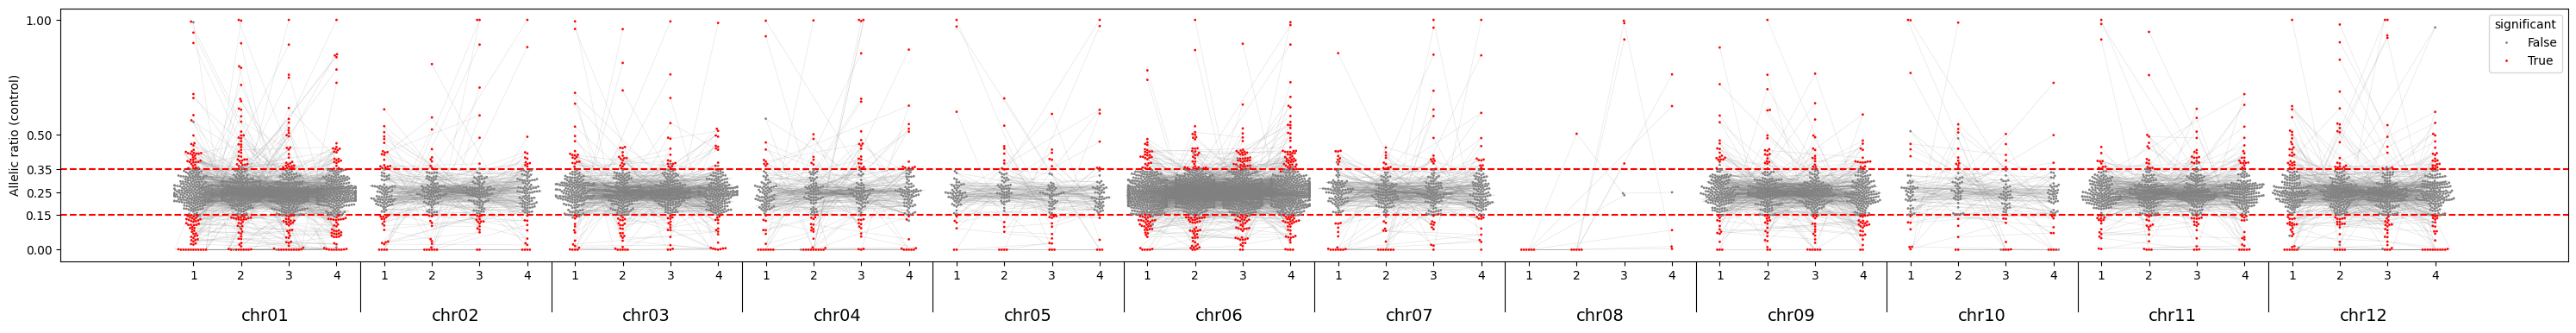

In [4]:
cis_4alleles = cis_results_control[cis_results_control["n_alleles"] == 4].copy()
cis_4alleles["chr_hap"] = cis_4alleles["chromosome"] + "." + cis_4alleles["allele"].str[-1]
# drop any row whose chr_hap doesn't cleanly parse to "<chrom>.<hap 1-4>"
cis_4alleles = cis_4alleles[~cis_4alleles["chr_hap"].str.contains(r"[^0-9\.1-4]")]
cis_4alleles["significant"] = (cis_4alleles["FDR"] < 0.05) & (cis_4alleles["ratio_difference"] > 0.1)

fig, ax = plt.subplots(figsize=(30, 4))
sns.swarmplot(y=cis_4alleles["ratios_control_mean"], x=cis_4alleles["chr_hap"],
              hue=cis_4alleles["significant"], size=2, ax=ax,
              palette={True: "red", False: "grey"}, order=CHR_HAP_ORDER)

# seaborn does not expose which plotted point belongs to which row, so match plotted swarm
# positions back to the dataframe by (approximate) x/y position
plotted_points = [{"x": x, "y": y} for coll in ax.collections for x, y in coll.get_offsets().data]
point_positions = {}
for idx, row in cis_4alleles.iterrows():
    chr_hap_x = CHR_HAP_ORDER.index(row["chr_hap"])
    for point in plotted_points:
        if abs(point["y"] - row["ratios_control_mean"]) < 0.001 and abs(point["x"] - chr_hap_x) < 0.5:
            point_positions.setdefault(idx, (point["x"], point["y"]))
            break

# connect the haplotypes of each syntelog with a faint line
for synt_id, subset in cis_4alleles.groupby("Synt_id"):
    valid_idx = [i for i in subset.index if i in point_positions]
    for i in range(len(valid_idx) - 1):
        x_vals = [point_positions[valid_idx[i]][0], point_positions[valid_idx[i + 1]][0]]
        y_vals = [point_positions[valid_idx[i]][1], point_positions[valid_idx[i + 1]][1]]
        ax.plot(x_vals, y_vals, color="gray", linewidth=0.5, alpha=0.2, zorder=0)

ax.set_yticks([0.0, 0.15, 0.25, 0.35, 0.5, 1.0])
ax.set_xticks(range(48))
ax.set_xticklabels(np.tile(np.arange(1, 5), 12))
ax.axhline(y=0.35, color="r", linestyle="--")
ax.axhline(y=0.15, color="r", linestyle="--")
ax.set_xlabel(None)
ax.set_ylabel("Allelic ratio (control)")

# chromosome labels + separators below the haplotype tick labels
trans = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
n_chrs, n_haps = 12, 4
chr_centers   = np.array([i * n_haps + 1.5 for i in range(n_chrs)])
sep_positions = np.array([n_haps * (i + 1) - 0.5 for i in range(n_chrs - 1)])
for i, pos in enumerate(chr_centers):
    ax.text(pos, -0.25, f"chr{i + 1:02d}", transform=trans, ha="center", va="bottom",
            fontsize=14, clip_on=False)
for pos in sep_positions:
    ax.plot([pos, pos], [0, -0.20], transform=trans, color="black", lw=0.8, clip_on=False)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/Fig2B_allelic_ratios_swarm_connected.svg", bbox_inches="tight")
plt.show()


## Panel C — Promoter SVs vs. allelic log2FC, colored by TE class

`SV_analysis_50_one_sv.csv` holds, for every haplotype pair with exactly one structural variant
(>50bp) in the promoter, that SV's distance to the TSS, the allelic log2FC between the two
haplotypes, and the transposable-element class of the SV (from a BLAST search against a TE
library).

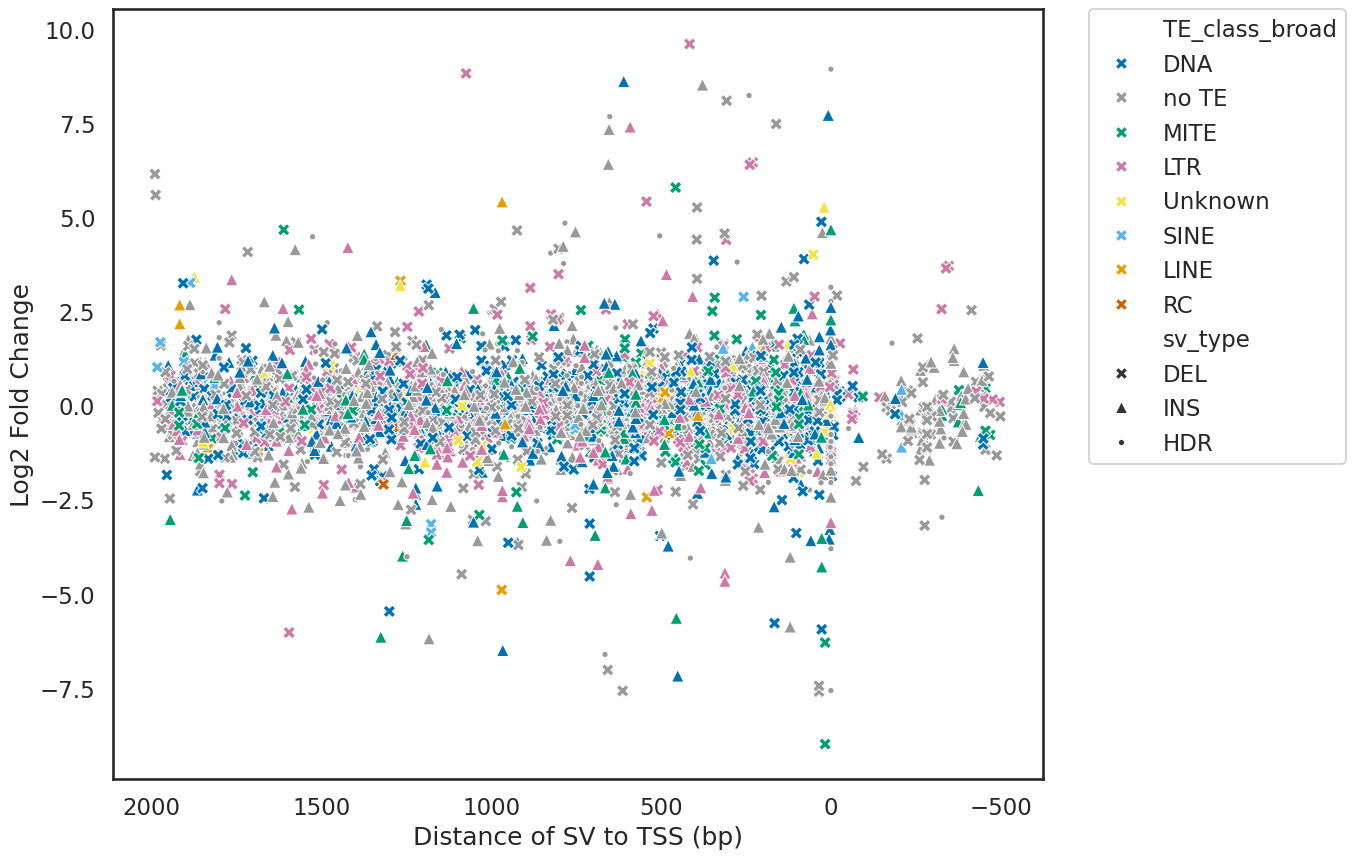

In [5]:
merged_grouped_one_sv = pd.read_csv(f"{DATA_DIR}/SV_analysis_50_one_sv.csv")
merged_grouped_one_sv["TE_class_broad"] = merged_grouped_one_sv["TE_class_broad"].replace("None", "no TE")

te_palette = {"no TE": "#999999", "DNA": "#0072B2", "LINE": "#E69F00", "LTR": "#CC79A7",
              "SINE": "#56B4E9", "MITE": "#009E73", "Unknown": "#F0E442", "rRNA": "#D55E00", "RC": "#D55E00"}

sns.set_theme(rc={"figure.figsize": (12, 10)}, context="talk", style="white")
ax = sns.scatterplot(
    data=merged_grouped_one_sv, x="ref_dist_tss", y="log2FC",
    style="sv_type", markers={"INS": "^", "DEL": "X", "HDR": "."},
    hue="TE_class_broad", palette=te_palette, alpha=1, sizes=(40, 300))
ax.invert_xaxis()
ax.set_xlabel("Distance of SV to TSS (bp)")
ax.set_ylabel("Log2 Fold Change")
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.0)

# # label the most extreme responses with their TE class
# for _, row in merged_grouped_one_sv.iterrows():
#     if abs(row["log2FC"]) > 3:
#         ax.text(row["ref_dist_tss"] + 0.01, row["log2FC"], row["TE_class_broad"],
#                 horizontalalignment="left", size=15, color="black")

plt.savefig(f"{OUT_DIR}/Fig2C_SV_distance_vs_log2FC_TE_class.svg", format="svg", dpi=300, bbox_inches="tight")
plt.show()


## Panel D — Case study: a cytochrome P450 gene with a haplotype-specific LTR insertion

`Soltu.DM.06G029570` shows one haplotype (Hap4) with strongly reduced expression relative to
the other three (log2FC vs. Hap4: +3.70 for Hap1, +3.64 for Hap2, +2.56 for Hap3, all
FDR < 1e-5). Its promoter carries an LTR insertion not present on the other haplotypes.

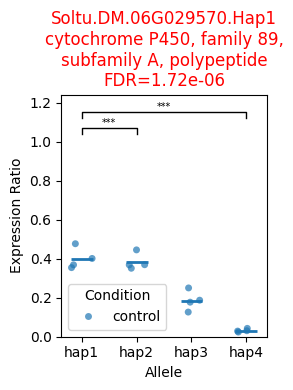

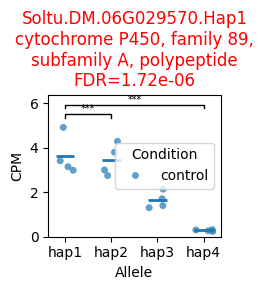

In [6]:
plt.rcParams.update(plt.rcParamsDefault)
gene_id = "Soltu.DM.06G029570"

cis_gene = cis_results_control[cis_results_control["gene_id"].str.contains(gene_id)]

poly.plot_top_differential_syntelogs_annotated(cis_gene, n=20, figsize=(14, 4), sort_by="ratio_difference")
poly.plot_top_differential_syntelogs_annotated(cis_gene, n=20, figsize=(12, 3),
                                                sort_by="ratio_difference", plot_type="cpm")
plt.savefig(f"{OUT_DIR}/Fig2D_cytochrome_allelic_ratios_cpm_{gene_id}.svg",
            format="svg", dpi=300, bbox_inches="tight")
plt.show()

## Panels E/F — Allele-specific expression at promoters shared between Désirée and Atlantic

Haplotype pairs tested for allelic imbalance in both cultivars (polyase pairwise cis test, control
condition) whose promoters (1,500 bp) are identical between a Désirée and an Atlantic haplotype for
both alleles (BLAST, no mismatches); chr08 genes excluded. Built by `prepare_fig2EF_atlantic.py`:
- `atlantic_desiree_shared_promoter_pairs.csv`: matched allele pairs per gene; `significant_in_both`
  marks pairs significantly imbalanced in both cultivars
- `atlantic_desiree_allele_cpm_control.csv`: CPM per allele in the control samples
  (Désirée DE_C_H_13–16; Atlantic SRR14993894, SRR14993895, SRR14996168)

log2FC(haplotype_i / haplotype_j) is computed from the mean control CPM of each allele.

In [7]:
from scipy import stats

pairs = pd.read_csv(f"{DATA_DIR}/atlantic_desiree_shared_promoter_pairs.csv")
cpm_long = pd.read_csv(f"{DATA_DIR}/atlantic_desiree_allele_cpm_control.csv")
mean_cpm = cpm_long.groupby(["cultivar", "allele_id"])["CPM"].mean()

def allele_log2fc(cultivar, allele_i, allele_j):
    return np.log2(mean_cpm[cultivar].reindex(allele_i).values / mean_cpm[cultivar].reindex(allele_j).values)

fc_df = pairs[pairs["in_panel_E"]].copy()
fc_df["log2FC_des"] = allele_log2fc("Désirée", fc_df["DES_allele_i"], fc_df["DES_allele_j"])
fc_df["log2FC_atl"] = allele_log2fc("Atlantic", fc_df["ATL_allele_i"], fc_df["ATL_allele_j"])
print("genes:", len(fc_df), "| significant in both cultivars:", fc_df["significant_in_both"].sum())

genes: 43 | significant in both cultivars: 6


### Panel E — Désirée vs. Atlantic allelic log2FC

Pearson r = 0.826, p = 9.33e-12, n = 43


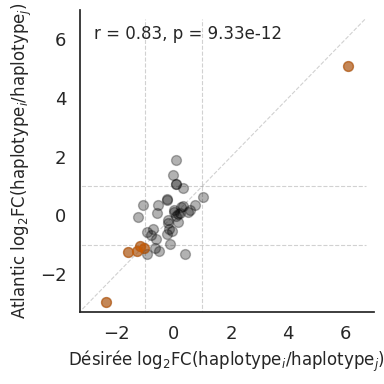

In [8]:
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(fc_df["log2FC_des"], fc_df["log2FC_atl"], alpha=0.3, s=50, c="black")
sig = fc_df[fc_df["significant_in_both"]]
ax.scatter(sig["log2FC_des"], sig["log2FC_atl"], color="#D55E00", s=50, zorder=4, alpha=0.5)

lim = max(fc_df["log2FC_des"].abs().max(), fc_df["log2FC_atl"].abs().max()) * 1.1
ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8, alpha=0.2)
for v in (-1, 1):
    ax.plot([-lim, lim], [v, v], "k--", lw=0.8, alpha=0.2)
    ax.plot([v, v], [-lim, lim], "k--", lw=0.8, alpha=0.2)
ax.set_xlim(-3.3, 7)
ax.set_ylim(-3.3, 7)
ax.set_xticks([-2, 0, 2, 4, 6])
ax.set_yticks([-2, 0, 2, 4, 6])
ax.set_xlabel("Désirée log$_2$FC(haplotype$_i$/haplotype$_j$)")
ax.set_ylabel("Atlantic log$_2$FC(haplotype$_i$/haplotype$_j$)")
ax.tick_params(axis="both", which="major", labelsize=13)

r, p = stats.pearsonr(fc_df["log2FC_des"], fc_df["log2FC_atl"])
print(f"Pearson r = {r:.3f}, p = {p:.3g}, n = {len(fc_df)}")
ax.text(0.05, 0.95, f"r = {r:.2f}, p = {p:.3}", transform=ax.transAxes, fontsize=12, va="top")
sns.despine()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/Fig2E_Desiree_vs_Atlantic_allelic_log2FC.svg", format="svg")
plt.show()

### Panel F — Conserved allele-specific expression: example genes

Three of the six genes significantly imbalanced in both cultivars (orange in panel E). x-axis numbers
are the haplotypes compared (haplotype_i filled, haplotype_j open); each dot is one control replicate.

all genes significant in both: ['Soltu.DM.01G002150', 'Soltu.DM.01G005630', 'Soltu.DM.02G003240', 'Soltu.DM.06G033690', 'Soltu.DM.06G034890', 'Soltu.DM.07G015350']


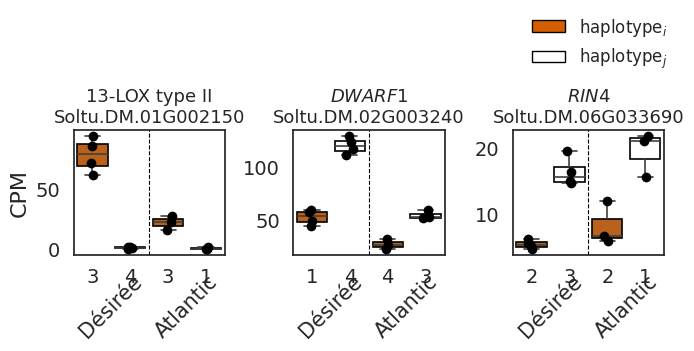

In [9]:
EXAMPLE_GENES = {
    "Soltu.DM.01G002150": "13-LOX type II",
    "Soltu.DM.02G003240": "$\\it{DWARF1}$",
    "Soltu.DM.06G033690": "$\\it{RIN4}$",
}
print("all genes significant in both:", pairs.loc[pairs["significant_in_both"], "Unitato_gene_id"].tolist())

fig, axes = plt.subplots(1, len(EXAMPLE_GENES), figsize=(2.3 * len(EXAMPLE_GENES), 3.8))
for ax, (gene, name) in zip(axes, EXAMPLE_GENES.items()):
    row = pairs.set_index("Unitato_gene_id").loc[gene]
    alleles = [("Désirée", row["DES_allele_i"]), ("Désirée", row["DES_allele_j"]),
               ("Atlantic", row["ATL_allele_i"]), ("Atlantic", row["ATL_allele_j"])]
    keys = [f"{cultivar}::{allele}" for cultivar, allele in alleles]
    df = pd.concat([
        cpm_long[(cpm_long["cultivar"] == cultivar) & (cpm_long["allele_id"] == allele)].assign(key=key)
        for (cultivar, allele), key in zip(alleles, keys)
    ])

    sns.boxplot(data=df, x="key", y="CPM", order=keys, hue="key", hue_order=keys, legend=False,
                palette=["#D55E00", "white", "#D55E00", "white"], linewidth=1.2, ax=ax)
    for patch in ax.patches:
        patch.set_edgecolor("black")
    sns.stripplot(data=df, x="key", y="CPM", order=keys, color="black", size=7, jitter=True, ax=ax)
    ax.axvline(1.5, color="black", ls="--", lw=0.8)

    ax.set_xticks(range(4))
    ax.set_xticklabels([allele[-1] for _, allele in alleles], fontsize=14)
    ax.tick_params(axis="y", labelsize=14)
    ax.set_xlabel("")
    ax.set_ylabel("CPM" if ax is axes[0] else "", fontsize=16)
    ax.set_title(f"{name}\n{gene}", fontsize=13)
    for x_center, cultivar in [(0.5, "Désirée"), (2.5, "Atlantic")]:
        ax.text(x_center, -0.13, cultivar, transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=15, rotation=45)

handles = [mpatches.Patch(facecolor="#D55E00", edgecolor="black", label="haplotype$_i$"),
           mpatches.Patch(facecolor="white", edgecolor="black", label="haplotype$_j$")]
plt.tight_layout(rect=(0, 0, 1, 0.82))
fig.legend(handles=handles, loc="upper right", bbox_to_anchor=(1, 1), frameon=False, fontsize=12)
plt.savefig(f"{OUT_DIR}/Fig2F_Desiree_Atlantic_shared_ASE_examples.svg", format="svg", bbox_inches="tight")
plt.show()